  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  
(541909, 8)
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 e

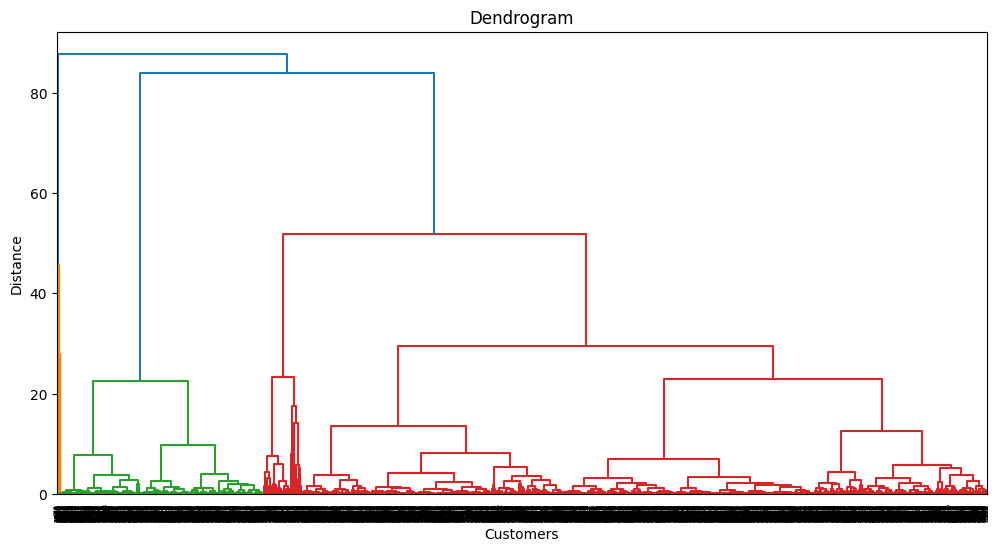

            Frequency  Monetary  Recency  Cluster
CustomerID                                       
12346.0             1  77183.60      325        0
12347.0             7   4310.00        1        0
12348.0             4   1797.24       74        0
12349.0             1   1757.55       18        0
12350.0             1    334.40      309        2
Cluster
0    3375
2     949
1      15
Name: count, dtype: int64


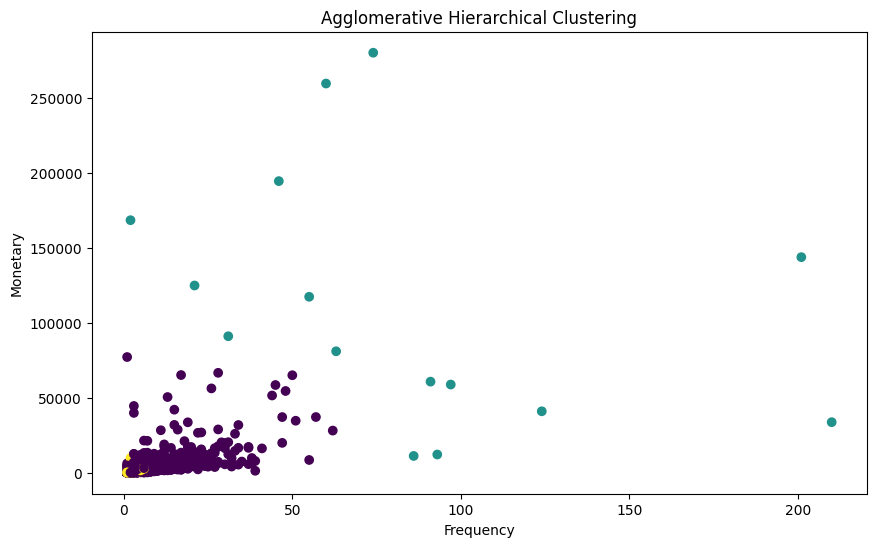

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

df = pd.read_csv("OnlineRetail.csv", encoding="latin1")

print(df.head())
print(df.shape)
print(df.columns)

print(df.info())
print(df.isnull().sum())

df = df.dropna(subset=["CustomerID"])
print(df.shape)

df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print(df.shape)

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print(df[["Quantity", "UnitPrice", "TotalAmount"]].head())

customer_data = df.groupby("CustomerID").agg({
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

customer_data.columns = ["Frequency", "Monetary"]

print(customer_data.head())
print(customer_data.shape)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

latest_date = df["InvoiceDate"].max()
print(latest_date)

recency = df.groupby("CustomerID")["InvoiceDate"].max().apply(
    lambda x: (latest_date - x).days
)

customer_data["Recency"] = recency

print(customer_data.head())

print(customer_data.describe())

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    customer_data[["Recency", "Frequency", "Monetary"]]
)

print(rfm_scaled[:5])

Z = linkage(rfm_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()

n_clusters = 3

model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward"
)

customer_data["Cluster"] = model.fit_predict(rfm_scaled)

print(customer_data.head())
print(customer_data["Cluster"].value_counts())

plt.figure(figsize=(10, 6))
plt.scatter(
    customer_data["Frequency"],
    customer_data["Monetary"],
    c=customer_data["Cluster"]
)

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Frequency")
plt.ylabel("Monetary")
plt.show()